# Credit Risk Modeling - Phase 3: Explainability, Reason Codes and Fairness

Builds on Phase 1 (evaluation) and Phase 2 (WoE scorecard as champion, XGBoost as challenger).

1. **SHAP for XGBoost**: global importance and the shape the model learned, compared with the scorecard bins.
2. **Reason codes**: why an applicant was declined, using three selection methods
   (max points, and the two average-based examples in the US Regulation B commentary), compared with SHAP.
3. **Fairness audit** by sex and age group: approval rates, disparate impact ratio, error rates and calibration per group.
4. **Proxy check**: how well the model inputs can reconstruct `Sex`, which was excluded in Phase 1.
5. **Experiment**: scorecard without `Age` - what it costs in AUC and what it changes for younger applicants.

Same data preparation, split (`random_state=42`) and model settings as Phase 2, so all models are identical.

## 1. Setup

In [1]:
# On Colab:
!pip install -q optbinning

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from optbinning import BinningProcess, Scorecard
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

import optbinning, sklearn, xgboost
print("optbinning", optbinning.__version__,
      "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

RANDOM_STATE = 42

(CVXPY) Nov 09 09:28:39 PM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')
(CVXPY) Nov 09 09:28:39 PM: Encountered unexpected exception importing solver GLOP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.12.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Nov 09 09:28:39 PM: Encountered unexpected exception importing solver PDLP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.12.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Nov 09 09:28:39 PM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')


optbinning 1.0.0 | scikit-learn 1.6.1 | xgboost 3.4.1


## 2. Data and split (identical to Phases 1-2, protected attributes kept aside)

In [2]:
LOCAL_CSV = os.environ.get("CREDIT_CSV")
if LOCAL_CSV:
    csv_path = LOCAL_CSV
else:
    import kagglehub
    path = kagglehub.dataset_download("kabure/german-credit-data-with-risk")
    csv_path = os.path.join(path, "german_credit_data.csv")

df = pd.read_csv(csv_path).drop(columns=["Unnamed: 0"], errors="ignore")
df[["Saving accounts", "Checking account"]] = df[["Saving accounts", "Checking account"]].fillna("none")
df["target"] = (df["Risk"] == "bad").astype(int)

num_features = ["Age", "Credit amount", "Duration"]
cat_features = ["Job", "Housing", "Saving accounts", "Checking account", "Purpose"]
features = num_features + cat_features

X = df[features].copy()
X["Job"] = X["Job"].astype(str)
y = df["target"]
sex = df["Sex"]

X_train, X_test, y_train, y_test, sex_train, sex_test = train_test_split(
    X, y, sex, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
y_tr, y_te = y_train.to_numpy(), y_test.to_numpy()
print(X_train.shape, X_test.shape)
print(pd.crosstab(df["Sex"], df["Risk"], margins=True))

100%|██████████| 11.2k/11.2k [00:00<00:00, 14.7MB/s]

Extracting files...
(800, 8) (200, 8)


Risk    bad  good   All
Sex                    
female  109   201   310
male    191   499   690
All     300   700  1000


## 3. Re-fit the Phase 2 models (same configuration, deterministic)

In [3]:
binning_fit_params = {
    "Duration": {"monotonic_trend": "ascending"},
    "Age": {"monotonic_trend": "auto_asc_desc"},
    "Credit amount": {"monotonic_trend": "auto_asc_desc"},
}
selection_criteria = {"iv": {"min": 0.02}}

def make_binning(var_names=features):
    return BinningProcess(
        variable_names=var_names,
        categorical_variables=[c for c in cat_features if c in var_names],
        min_bin_size=0.05,
        binning_fit_params={k: v for k, v in binning_fit_params.items() if k in var_names},
        selection_criteria=selection_criteria,
    )

PDO, BASE_SCORE, BASE_ODDS = 20, 600, 50
factor = PDO / np.log(2)
offset = BASE_SCORE - factor * np.log(BASE_ODDS)

def pd_to_score(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return offset + factor * np.log((1 - p) / p)

def make_scorecard(var_names=features):
    return Scorecard(
        binning_process=make_binning(var_names),
        estimator=LogisticRegression(C=1e3, max_iter=1000),
        scaling_method="pdo_odds",
        scaling_method_params={"pdo": PDO, "odds": BASE_ODDS, "scorecard_points": BASE_SCORE},
    )

scorecard = make_scorecard().fit(X_train, y_train)
sc_vars = [str(v) for v in scorecard.binning_process_.get_support(names=True)]
sc_coef = pd.Series(scorecard.estimator_.coef_[0], index=sc_vars)

xgb_pipe = Pipeline([
    ("prep", ColumnTransformer([
        ("num", "passthrough", num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ])),
    ("model", XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.03, subsample=0.8,
                            colsample_bytree=0.8, scale_pos_weight=1,
                            random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1)),
]).fit(X_train, y_train)

test_score = scorecard.score(X_test)
print("Scorecard variables:", sc_vars)
print("Test AUC - scorecard:", round(roc_auc_score(y_te, -test_score), 3),
      "| XGBoost:", round(roc_auc_score(y_te, xgb_pipe.predict_proba(X_test)[:, 1]), 3))

Scorecard variables: ['Age', 'Credit amount', 'Duration', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']
Test AUC - scorecard: 0.78 | XGBoost: 0.785


In [4]:
# Out-of-fold scorecard PDs on the training set and the Phase 2 cut-offs (should reproduce Phase 2)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
woe_lr = Pipeline([("binning", make_binning()), ("lr", LogisticRegression(C=1e3, max_iter=1000))])
oof_pd = cross_val_predict(woe_lr, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
oof_score = pd_to_score(oof_pd)

COST_FN, COST_FP = 5, 1
def cost_per_applicant(y_true, score, cutoff):
    approved = score >= cutoff
    fn = (approved & (y_true == 1)).sum()
    fp = (~approved & (y_true == 0)).sum()
    return (COST_FN * fn + COST_FP * fp) / len(y_true)

grid = np.arange(np.floor(oof_score.min()), np.ceil(oof_score.max()) + 1, 0.5)
cost_cutoff = float(grid[np.argmin([cost_per_applicant(y_tr, oof_score, c) for c in grid])])
cutoff_50 = float(np.quantile(oof_score, 0.5))
CUTOFFS = {"cost-optimal": cost_cutoff, "approve ~50%": cutoff_50}
print({k: round(v, 1) for k, v in CUTOFFS.items()})

{'cost-optimal': 535.5, 'approve ~50%': 516.3}


## 4. SHAP for XGBoost

SHAP values are computed with XGBoost's built-in TreeSHAP (`pred_contribs=True`), which gives exact values
for tree models. SHAP splits each prediction (in log-odds of **bad**) into a base value plus one contribution per input:
`logit(PD) = base value + sum(SHAP values)`. Positive SHAP pushes towards bad.

One-hot columns are summed back to their original variable, which is valid because SHAP values are additive.
SHAP explains the **model**, not the real world: with correlated inputs (Duration and Credit amount)
credit is split between them in a way that does not imply causation.

In [5]:
prep = xgb_pipe.named_steps["prep"]
xgb_model = xgb_pipe.named_steps["model"]
booster = xgb_model.get_booster()

enc_names = prep.get_feature_names_out()

def original_feature(enc_name):
    # 'num__Age' -> 'Age'; 'cat__Saving accounts_little' -> 'Saving accounts'
    raw = enc_name.split("__", 1)[1]
    for f in features:
        if raw == f or raw.startswith(f + "_"):
            return f
    raise ValueError(enc_name)

col_map = [original_feature(n) for n in enc_names]

def shap_by_feature(X_part):
    # IMPORTANT: keep the preprocessor output exactly as the model saw it during training.
    # The ColumnTransformer returns a sparse matrix here; XGBoost treats absent sparse entries
    # (the zeros of the one-hot columns) as MISSING. Densifying it turns them into real zeros,
    # which follow a different branch and explains a different model.
    Z = prep.transform(X_part)
    contrib = booster.predict(xgboost.DMatrix(Z), pred_contribs=True)  # TreeSHAP, last column = bias
    sv, bias = contrib[:, :-1], contrib[:, -1]
    out = pd.DataFrame(sv, columns=enc_names, index=X_part.index).T.groupby(col_map).sum().T
    return out[features], float(bias[0])

shap_train, base_value = shap_by_feature(X_train)
shap_test, _ = shap_by_feature(X_test)

# Additivity check against the PIPELINE prediction (what the app and Phases 1-2 actually use)
p_pipe = np.clip(xgb_pipe.predict_proba(X_test)[:, 1], 1e-9, 1 - 1e-9)
logit_xgb = np.log(p_pipe / (1 - p_pipe))
print("Base value (log-odds):", round(base_value, 3),
      "| max additivity error vs pipeline:", float(np.abs(base_value + shap_test.sum(axis=1) - logit_xgb).max()))

# Sanity check: mean SHAP of Checking account by category should follow its bad rate
print(shap_test["Checking account"].groupby(X_test["Checking account"]).mean().round(3))

Base value (log-odds): -0.856 | max additivity error vs pipeline: 1.5497207641601562e-06
Checking account
little      0.675
moderate    0.331
none       -0.974
rich        0.101
Name: Checking account, dtype: float32


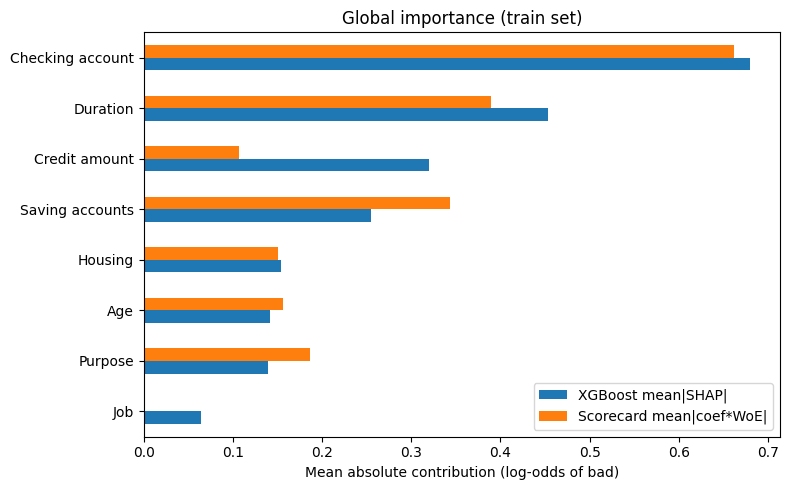

,XGBoost mean|SHAP|,Scorecard mean|coef*WoE|
Checking account,0.680,0.662
Duration,0.453,0.389
Credit amount,0.320,0.107
Saving accounts,0.255,0.343
Housing,0.153,0.151
Age,0.142,0.156
Purpose,0.140,0.186
Job,0.064,0.000


In [6]:
# Global importance: mean |SHAP| (XGBoost) vs mean |coef * WoE| (scorecard), both in log-odds units
woe_train = pd.DataFrame(scorecard.binning_process_.transform(X_train, metric="woe"),
                         columns=features, index=X_train.index)
sc_contrib_train = woe_train[sc_vars] * sc_coef  # contribution to log-odds of bad, WoE = 0 as reference

importance = pd.DataFrame({
    "XGBoost mean|SHAP|": shap_train.abs().mean(),
    "Scorecard mean|coef*WoE|": sc_contrib_train.abs().mean(),
}).fillna(0).sort_values("XGBoost mean|SHAP|")

importance.plot.barh(figsize=(8, 5))
plt.xlabel("Mean absolute contribution (log-odds of bad)")
plt.title("Global importance (train set)"); plt.tight_layout(); plt.show()
importance.sort_values("XGBoost mean|SHAP|", ascending=False).round(3)

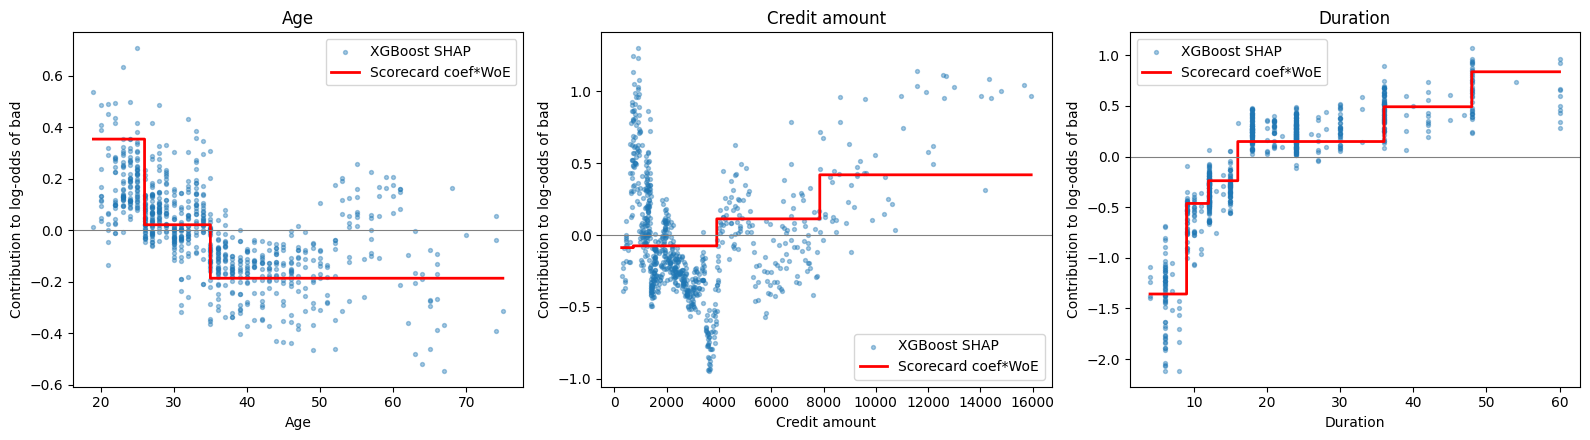

In [7]:
# Learned shape: XGBoost SHAP vs the scorecard step function for each numerical variable
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, var in zip(axes, num_features):
    ax.scatter(X_train[var], shap_train[var], s=8, alpha=0.4, label="XGBoost SHAP")
    if var in sc_vars:
        order = np.argsort(X_train[var].to_numpy())
        ax.step(X_train[var].to_numpy()[order], sc_contrib_train[var].to_numpy()[order],
                where="post", c="red", lw=2, label="Scorecard coef*WoE")
    ax.axhline(0, c="gray", lw=0.8)
    ax.set_xlabel(var); ax.set_ylabel("Contribution to log-odds of bad"); ax.set_title(var)
    ax.legend()
plt.tight_layout(); plt.show()

## 5. Reason codes

A declined applicant should be told the main reasons. With a points-based scorecard the reasons are
the variables where the applicant scored furthest below a **reference**. Three references:

- **A. Max points**: points lost vs the best bin of each variable. Common in practice, but it flags
  a variable even when the applicant is better than average on it (e.g. a normal 18-month loan).
- **B. Average of all applicants**: the second example method in the Regulation B commentary (comment 9(b)(2)-5).
- **C. Average of applicants at or slightly above the cut-off**: the first example method in that commentary.
  Here "slightly above" is taken as cut-off to cut-off + 10 points (a modelling choice).

At most four reasons are reported (the commentary notes more than four is unlikely to help the applicant).
For XGBoost, the reasons are the features with the largest positive SHAP values.

In [8]:
sc_table = scorecard.table(style="detailed")

def points_matrix(X_part):
    # Points per scorecard variable for every applicant
    bp = scorecard.binning_process_
    cols = {}
    for var in sc_vars:
        idx = bp.get_binned_variable(var).transform(X_part[var].to_numpy(), metric="indices")
        pts = sc_table.loc[sc_table["Variable"] == var, "Points"].to_numpy()
        cols[var] = pts[np.asarray(idx, dtype=int)]
    return pd.DataFrame(cols, index=X_part.index)

P_train, P_test = points_matrix(X_train), points_matrix(X_test)
print("Points matrix reproduces score:",
      np.allclose(P_test.sum(axis=1), test_score))

train_score = scorecard.score(X_train)
near_cut = (train_score >= cost_cutoff) & (train_score < cost_cutoff + 10)
references = {
    "A_max_points": sc_table.groupby("Variable")["Points"].max()[sc_vars],
    "B_avg_all": P_train.mean(),
    "C_avg_near_cutoff": P_train[near_cut].mean(),
}
print("Applicants used for reference C:", int(near_cut.sum()))
pd.DataFrame(references).round(1)

Points matrix reproduces score: True
Applicants used for reference C: 65


,A_max_points,B_avg_all,C_avg_near_cutoff
Age,78.4,73.4,74.0
Credit amount,75.6,73.3,74.2
Duration,112.2,74.9,78.2
Housing,76.3,73.3,74.7
Saving accounts,98.7,74.4,74.8
Checking account,100.9,76.6,90.5
Purpose,83.9,73.5,73.5


In [9]:
REASON_TEXT = {
    "Duration": "Loan duration is long",
    "Checking account": "Checking account status",
    "Saving accounts": "Savings account balance is low or unavailable",
    "Credit amount": "Requested credit amount",
    "Purpose": "Purpose of the loan",
    "Housing": "Housing status",
    "Age": "Age",
    "Job": "Employment / skill level",
}
MAX_REASONS = 4

def top_reasons(gap_row):
    # Variables with a positive gap (applicant below reference), largest first
    g = gap_row[gap_row > 1e-9].sort_values(ascending=False)
    return list(g.index[:MAX_REASONS])

def reasons_table(i):
    rows = {}
    for name, ref in references.items():
        rows[name] = top_reasons(ref - P_test.loc[i])
    shap_row = shap_test.loc[i]
    rows["XGBoost_SHAP"] = list(shap_row[shap_row > 0].sort_values(ascending=False).index[:MAX_REASONS])
    width = max(len(v) for v in rows.values())
    return pd.DataFrame({k: v + [""] * (width - len(v)) for k, v in rows.items()},
                        index=[f"reason {j + 1}" for j in range(width)])

# Example: the first declined test applicant under the cost-optimal cut-off
declined = X_test.index[test_score < cost_cutoff]
ex = declined[0]
print("Applicant", ex, "| score", round(float(test_score[X_test.index.get_loc(ex)]), 1),
      "| actual:", "bad" if y_test.loc[ex] == 1 else "good")
print(X_test.loc[ex].to_dict())
reasons_table(ex)

Applicant 30 | score 530.4 | actual: good
{'Age': 36, 'Credit amount': 1913, 'Duration': 18, 'Job': '2', 'Housing': 'own', 'Saving accounts': 'rich', 'Checking account': 'moderate', 'Purpose': 'business'}


,A_max_points,B_avg_all,C_avg_near_cutoff,XGBoost_SHAP
reason 1,Duration,Checking account,Checking account,Checking account
reason 2,Checking account,Duration,Duration,Duration
reason 3,Purpose,Purpose,Purpose,Credit amount
reason 4,Credit amount,,,


In [10]:
# Agreement between methods over all declined test applicants
methods = list(references) + ["XGBoost_SHAP"]
reason_sets = {m: {} for m in methods}
for i in declined:
    t = reasons_table(i)
    for m in methods:
        reason_sets[m][i] = [r for r in t[m] if r]

def agreement(m1, m2, k=3):
    top1, overlap = [], []
    for i in declined:
        a, b = reason_sets[m1][i], reason_sets[m2][i]
        top1.append(bool(a) and bool(b) and a[0] == b[0])
        sa, sb = set(a[:k]), set(b[:k])
        overlap.append(len(sa & sb) / k)
    return np.mean(top1), np.mean(overlap)

pairs = [("A_max_points", "B_avg_all"), ("B_avg_all", "C_avg_near_cutoff"),
         ("A_max_points", "C_avg_near_cutoff"), ("B_avg_all", "XGBoost_SHAP")]
agree = pd.DataFrame([{"pair": f"{a} vs {b}", "top1_agreement": agreement(a, b)[0],
                       "top3_overlap": agreement(a, b)[1]} for a, b in pairs]).round(3)
print("Declined test applicants:", len(declined))
agree

Declined test applicants: 132


,pair,top1_agreement,top3_overlap
0,A_max_points vs B_avg_all,0.636,0.790
1,B_avg_all vs C_avg_near_cutoff,0.833,0.886
2,A_max_points vs C_avg_near_cutoff,0.636,0.773
3,B_avg_all vs XGBoost_SHAP,0.667,0.795


In [11]:
# How often each variable is the number-one reason, by method
first_reason = pd.DataFrame({m: pd.Series([v[0] if v else "none" for v in reason_sets[m].values()])
                             .value_counts() for m in methods}).fillna(0).astype(int)
first_reason

,A_max_points,B_avg_all,C_avg_near_cutoff,XGBoost_SHAP
Age,0,6,5,4
Checking account,59,82,97,67
Credit amount,0,0,0,20
Duration,71,26,25,28
Housing,0,0,0,6
Purpose,0,8,5,4
Saving accounts,2,10,0,3


## 6. Fairness audit

Groups: `Sex` (excluded from the model) and age (`< 25` vs `25+`, a split commonly used with this dataset).
Measured on the 800 out-of-fold training scores (more stable) and confirmed on the 200-row test set.

Per group:
- **base bad rate**: the actual default rate (groups can genuinely differ).
- **approval rate** and **disparate impact (DI) ratio** = approval rate of the group / approval rate of the
  highest group. The 0.8 "four-fifths" rule from US employment guidance is a common screening heuristic, not a legal test for credit.
- **approval among good**: share of creditworthy customers approved (equal opportunity).
- **bad rate among approved**: whether a given decision means the same risk in each group.
- **mean PD vs base bad rate**: calibration within group.
- **AUC**: ranking quality within group.

When base rates differ, these criteria cannot all be equal at once (Kleinberg et al. 2016; Chouldechova 2017),
so the audit reports trade-offs rather than a single pass/fail.

In [12]:
age_train = np.where(X_train["Age"] < 25, "<25", "25+")
age_test = np.where(X_test["Age"] < 25, "<25", "25+")

def fairness_table(y_true, score, pdv, group, cutoff):
    rows = []
    for g in sorted(pd.unique(group)):
        m = group == g
        yt, approved = y_true[m], score[m] >= cutoff
        rows.append({
            "group": g, "n": int(m.sum()), "base_bad_rate": yt.mean(),
            "approval_rate": approved.mean(),
            "approval_among_good": approved[yt == 0].mean(),
            "bad_rate_among_approved": yt[approved].mean() if approved.any() else np.nan,
            "mean_pd": pdv[m].mean(),
            "auc": roc_auc_score(yt, pdv[m]) if 0 < yt.sum() < len(yt) else np.nan,
        })
    t = pd.DataFrame(rows)
    t["di_ratio"] = t["approval_rate"] / t["approval_rate"].max()
    return t

def di_bootstrap(y_true, score, group, cutoff, unpriv, priv, n_boot=1000):
    rng = np.random.default_rng(RANDOM_STATE)
    vals = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_true), len(y_true))
        a, g = score[i] >= cutoff, group[i]
        vals.append(a[g == unpriv].mean() / a[g == priv].mean())
    return np.percentile(vals, [2.5, 97.5])

test_pd = scorecard.predict_proba(X_test)[:, 1]
sex_tr, sex_te = sex_train.to_numpy(), sex_test.to_numpy()

for cut_name, cut in CUTOFFS.items():
    print(f"\n################ Cut-off: {cut_name} ({cut:.1f}) ################")
    for gname, g_tr, g_te, unpriv, priv in [("Sex", sex_tr, sex_te, "female", "male"),
                                            ("Age group", age_train, age_test, "<25", "25+")]:
        t_oof = fairness_table(y_tr, oof_score, oof_pd, g_tr, cut)
        lo, hi = di_bootstrap(y_tr, oof_score, g_tr, cut, unpriv, priv)
        t_test = fairness_table(y_te, test_score, test_pd, g_te, cut)
        print(f"\n--- {gname} | OOF (train) | DI {unpriv}/{priv} 95% CI: {lo:.2f} - {hi:.2f}")
        print(t_oof.round(3).to_string(index=False))
        print(f"--- {gname} | Test")
        print(t_test.round(3).to_string(index=False))


################ Cut-off: cost-optimal (535.5) ################

--- Sex | OOF (train) | DI female/male 95% CI: 0.69 - 1.07
 group   n  base_bad_rate  approval_rate  approval_among_good  bad_rate_among_approved  mean_pd   auc  di_ratio
female 249          0.357          0.313                0.438                    0.103    0.312 0.756     0.863
  male 551          0.274          0.363                0.455                    0.090    0.296 0.746     1.000
--- Sex | Test
 group   n  base_bad_rate  approval_rate  approval_among_good  bad_rate_among_approved  mean_pd   auc  di_ratio
female  61          0.328          0.295                0.390                    0.111    0.333 0.783      0.82
  male 139          0.288          0.360                0.455                    0.100    0.292 0.778      1.00

--- Age group | OOF (train) | DI <25/25+ 95% CI: 0.22 - 0.56
group   n  base_bad_rate  approval_rate  approval_among_good  bad_rate_among_approved  mean_pd   auc  di_ratio
  25+ 690      

## 7. Proxy check: can the inputs reconstruct `Sex`?

Dropping `Sex` does not guarantee the model ignores it if other inputs act as proxies.
We train a classifier to predict `Sex` from the model inputs. AUC near 0.5 means weak proxies;
a high AUC means the protected attribute is largely recoverable and outcomes should be monitored by group.

In [13]:
is_female = (sex_tr == "female").astype(int)
proxy_rows = []
for name, cols in [("All model inputs", features),
                   ("All inputs except Age", [f for f in features if f != "Age"]),
                   ("Age only", ["Age"])]:
    pipe = Pipeline([
        ("prep", ColumnTransformer([
            ("num", StandardScaler(), [c for c in cols if c in num_features]),
            ("cat", OneHotEncoder(handle_unknown="ignore"), [c for c in cols if c in cat_features]),
        ])),
        ("lr", LogisticRegression(max_iter=2000)),
    ])
    p = cross_val_predict(pipe, X_train[cols], is_female, cv=cv, method="predict_proba")[:, 1]
    proxy_rows.append({"inputs": name, "cv_auc_predict_female": roc_auc_score(is_female, p)})
pd.DataFrame(proxy_rows).round(3)

,inputs,cv_auc_predict_female
0,All model inputs,0.617
1,All inputs except Age,0.602
2,Age only,0.621


## 8. Age in the scorecard

`Age` is both a model input and a protected characteristic. US Regulation B, section 1002.6(b)(2)(ii),
allows age as a predictive variable in an empirically derived, demonstrably and statistically sound scoring
system, provided the age of an elderly applicant is not assigned a negative factor or value
(Regulation B defines elderly as 62 or older). Two checks:

1. The bin containing ages 62+ should not carry a negative WoE (or points below the neutral level).
2. Experiment: drop `Age` and measure the change in OOF AUC and in outcomes for applicants under 25.

In [14]:
ob_age = scorecard.binning_process_.get_binned_variable("Age") if "Age" in sc_vars else None
if ob_age is not None:
    bt_age = ob_age.binning_table.build()
    print(bt_age[["Bin", "Count", "Event rate", "WoE"]].to_string())
    woe_elderly = ob_age.transform(np.array([62, 70, 75]), metric="woe")
    print("\nWoE for ages 62, 70, 75:", np.round(woe_elderly, 3),
          "| non-negative:", bool((woe_elderly >= 0).all()))
else:
    print("Age was not selected by the scorecard.")

                   Bin  Count  Event rate       WoE
0        (-inf, 25.50)    146    0.410959 -0.487295
1       [25.50, 34.50)    297    0.306397 -0.030281
2         [34.50, inf)    357    0.249300  0.255053
3              Special      0    0.000000       0.0
4              Missing      0    0.000000       0.0
Totals                    800    0.300000          

WoE for ages 62, 70, 75: [0.255 0.255 0.255] | non-negative: True


In [15]:
no_age = [f for f in features if f != "Age"]
woe_lr_no_age = Pipeline([("binning", make_binning(no_age)),
                          ("lr", LogisticRegression(C=1e3, max_iter=1000))])
oof_pd_no_age = cross_val_predict(woe_lr_no_age, X_train[no_age], y_train, cv=cv,
                                  method="predict_proba")[:, 1]
oof_score_no_age = pd_to_score(oof_pd_no_age)
cut_no_age = float(grid[np.argmin([cost_per_applicant(y_tr, oof_score_no_age, c) for c in grid])])

fold_auc = lambda p: [roc_auc_score(y_tr[va], p[va]) for _, va in cv.split(X_train, y_train)]
d = np.array(fold_auc(oof_pd_no_age)) - np.array(fold_auc(oof_pd))
print(f"OOF AUC with Age: {roc_auc_score(y_tr, oof_pd):.3f} | without Age: {roc_auc_score(y_tr, oof_pd_no_age):.3f}")
print(f"Paired fold difference (without - with): {d.mean():+.3f} (std {d.std():.3f})")
print(f"Cost-optimal cut-off with Age: {cost_cutoff:.1f} | without Age: {cut_no_age:.1f}")

cmp = pd.concat({
    "with Age": fairness_table(y_tr, oof_score, oof_pd, age_train, cost_cutoff).set_index("group"),
    "without Age": fairness_table(y_tr, oof_score_no_age, oof_pd_no_age, age_train, cut_no_age).set_index("group"),
})[["n", "base_bad_rate", "approval_rate", "approval_among_good", "bad_rate_among_approved", "di_ratio"]]
cmp.round(3)

OOF AUC with Age: 0.750 | without Age: 0.748
Paired fold difference (without - with): -0.002 (std 0.005)
Cost-optimal cut-off with Age: 535.5 | without Age: 536.5


n  base_bad_rate  approval_rate  approval_among_good  \
            group                                                           
with Age    25+    690          0.287          0.380                0.482   
            <25    110          0.382          0.145                0.221   
without Age 25+    690          0.287          0.357                0.457   
            <25    110          0.382          0.218                0.309   

                   bad_rate_among_approved  di_ratio  
            group                                     
with Age    25+                      0.095     1.000  
            <25                      0.062     0.383  
without Age 25+                      0.085     1.000  
            <25                      0.125     0.612

## 9. Save reason-code references for the app

In [18]:
# Final champion: WoE scorecard without Age (decision from the Section 8 experiment)
features_final = [f for f in features if f != "Age"]
cat_final = [c for c in cat_features if c in features_final]
num_final = [c for c in num_features if c in features_final]

scorecard_final = make_scorecard(features_final).fit(X_train[features_final], y_train)
final_vars = [str(v) for v in scorecard_final.binning_process_.get_support(names=True)]
final_coef = pd.Series(scorecard_final.estimator_.coef_[0], index=final_vars)
print("Variables:", final_vars)
print(final_coef.round(3).to_string())
print("All coefficients negative:", bool((final_coef < 0).all()))

# Cut-off chosen out-of-fold in Section 8 (cut_no_age); evaluated once on the test set
test_score_final = scorecard_final.score(X_test[features_final])
approved_test = test_score_final >= cut_no_age
print(f"Test AUC: {roc_auc_score(y_te, -test_score_final):.3f} | cut-off: {cut_no_age:.1f} | "
      f"test approval rate: {approved_test.mean():.3f} | "
      f"bad rate among approved: {y_te[approved_test].mean():.3f}")

# Reason-code reference (method B): average points per variable over training applicants
final_table = scorecard_final.table(style="detailed")
bp_final = scorecard_final.binning_process_
reason_ref_final = {}
for var in final_vars:
    idx = bp_final.get_binned_variable(var).transform(X_train[var].to_numpy(), metric="indices")
    pts = final_table.loc[final_table["Variable"] == var, "Points"].to_numpy()
    reason_ref_final[var] = float(pts[np.asarray(idx, dtype=int)].mean())

artifact = {
    "scorecard": scorecard_final,
    "features": features_final,
    "num_features": num_final,
    "cat_features": cat_final,
    "scaling": {"pdo": PDO, "base_score": BASE_SCORE, "base_odds": BASE_ODDS,
                "factor": factor, "offset": offset},
    "cost_cutoff": cut_no_age,
    "reason_reference": reason_ref_final,
    "reason_text": REASON_TEXT,
    "max_reasons": MAX_REASONS,
    "platt": None,  # evaluated in Phase 2, not applied
    "positive_class": "bad",
    "model_note": "WoE scorecard without Age (fairness decision, Phase 3)",
}
joblib.dump(artifact, "credit_scorecard.pkl")
print("Saved credit_scorecard.pkl (final champion, no Age)")

Variables: ['Credit amount', 'Duration', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']
Credit amount      -0.354
Duration           -0.877
Housing            -0.604
Saving accounts    -0.808
Checking account   -0.859
Purpose            -0.757
All coefficients negative: True
Test AUC: 0.763 | cut-off: 536.5 | test approval rate: 0.335 | bad rate among approved: 0.134
Saved credit_scorecard.pkl (final champion, no Age)


## 10. Notes and limitations

- Group sizes are small (especially applicants under 25 and the test set), so group metrics carry wide uncertainty; see the bootstrap intervals.
- The `Sex` column in the Kaggle file appears to be derived from the UCI attribute "personal status and sex" (TODO: verify against the UCI documentation before citing).
- SHAP and the scorecard explain the models, not causal effects.
- Regulation B is US law and has been amended (section 1002.6(a) on the effects test changed in 2026); it is used here as a reference framework for reason codes and age, not as legal advice. Other jurisdictions have their own rules.